# 🛰️ RESQVISION — Satellite Damage Classification Training Pipeline

Full-dataset training pipeline for the **Vision AI** component of RESQVISION
(AI-based Search & Rescue from Satellite Imagery).

Dataset: Kaggle "Satellite Images of Hurricane Damage"
https://www.kaggle.com/datasets/kmader/satellite-images-of-hurricane-damage

**Policy**
- Uses the COMPLETE dataset (no artificial subsetting).
- Speed comes from GPU + AMP + efficient DataLoaders + a short *initial*
  training run, not from shrinking the data.
- Test set is touched exactly once, at the very end.
- All reported numbers come from actual execution — nothing is fabricated.

Pipeline:

```
Kaggle Dataset -> Inspection -> Cleaning -> Leakage Check -> Split
 -> Preprocessing -> Augmentation -> DataLoader
 -> ResNet-18 baseline -> EfficientNet-B0 initial -> Validation
 -> Extended fine-tuning -> Calibration -> Final Test Evaluation
 -> Grad-CAM -> Save Best Model
```

## STEP 1 — Environment & Dependency Check

In [23]:
import sys, os, subprocess

REQUIRED = ["torch", "torchvision", "sklearn", "PIL", "numpy", "pandas", "matplotlib"]

missing = []
for pkg in REQUIRED:
    try:
        __import__(pkg if pkg != "PIL" else "PIL")
    except ImportError:
        missing.append("scikit-learn" if pkg == "sklearn" else ("pillow" if pkg == "PIL" else pkg))

if missing:
    print("Installing missing packages:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "--break-system-packages", "-q", *missing])

import torch, torchvision
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("CUDA avail  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
    print("GPU memory  : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

Python      : 3.12.13
PyTorch     : 2.10.0+cu128
Torchvision : 0.25.0+cu128
CUDA avail  : True
GPU         : Tesla T4
GPU memory  : 15.6 GB


## STEP 2 — Config

In [24]:
import random
import numpy as np
import torch

class CFG:
    # ---- reproducibility ----
    SEED = 42

    # ---- dataset ----
    DATA_ROOT = None          # auto-detected in STEP 3, or set manually e.g. "/kaggle/input/satellite-images-of-hurricane-damage"
    IMG_SIZE = 224
    MEAN = [0.485, 0.456, 0.406]
    STD  = [0.229, 0.224, 0.225]

    # ---- split ----
    TRAIN_FRAC = 0.8
    VAL_FRAC   = 0.1
    TEST_FRAC  = 0.1

    # ---- dataloader ----
    NUM_WORKERS = min(4, os.cpu_count() or 2)
    PIN_MEMORY = torch.cuda.is_available()

    # ---- training ----
    RESNET_EPOCHS = 6                 # ~5-8, configurable
    EFFNET_INITIAL_EPOCHS = 5         # frozen backbone, short full-dataset run
    EFFNET_INITIAL_LR = 1e-3

    EFFNET_FT_MAX_EPOCHS = 20         # 15-25 range, capped by early stopping
    EFFNET_FT_LR = 1e-4
    EARLY_STOPPING_PATIENCE = 5

    WEIGHT_DECAY = 1e-4

    # ---- primary metric ----
    PRIMARY_METRIC = "val_f1"

    # ---- output ----
    OUT_DIR = "resqvision_artifacts"
    MODELS_DIR = os.path.join(OUT_DIR, "models")

import os
os.makedirs(CFG.MODELS_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # deterministic-ish, documenting the perf tradeoff of full determinism
    torch.backends.cudnn.benchmark = True

set_seed(CFG.SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Seed         :", CFG.SEED)
print("Device       :", DEVICE)

Seed         : 42
Device       : cuda


## STEP 3 — Dataset Path Detection

In [25]:
import glob

IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")

def has_images(path, sample=20):
    try:
        entries = os.listdir(path)
    except Exception:
        return False
    n = 0
    for f in entries:
        if f.lower().endswith(IMG_EXTS):
            n += 1
            if n >= 1:
                return True
        if n >= sample:
            break
    return False

def looks_like_class_dir(path):
    """A directory is a 'class root' if it directly contains >=2 subfolders
    that themselves contain image files."""
    if not os.path.isdir(path):
        return False
    subdirs = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
    hits = sum(1 for d in subdirs if has_images(os.path.join(path, d)))
    return hits >= 2

SPLIT_NAME_MAP = {
    "train": "train", "training": "train", "train_another": "train",
    "val": "val", "valid": "val", "validation": "val", "validation_another": "val",
    "test": "test", "testing": "test", "test_another": "test",
}

def find_split_roots(base):
    """Look for an official train/val/test layout directly under `base`:
    base/<split_dir>/<class_dir>/*.jpg
    Handles this dataset's actual folder names: train_another/, validation_another/,
    test_another/ — each holding damage/ and no_damage/."""
    if not os.path.isdir(base):
        return None
    found = {}
    for d in os.listdir(base):
        dpath = os.path.join(base, d)
        key = SPLIT_NAME_MAP.get(d.lower())
        if key and looks_like_class_dir(dpath):
            found[key] = dpath
    if "train" in found and "test" in found:
        return found
    return None

def walk_search(start, max_depth=5):
    """Recursively walk `start` (bounded depth) and return the FIRST directory
    that is either an official split root or a flat class-folder root.
    This replaces fixed-depth glob patterns, which miss datasets nested at an
    unpredictable depth (a very common Kaggle 'input' issue)."""
    if not start or not os.path.isdir(start):
        return None

    start_depth = start.rstrip("/").count(os.sep)
    for dirpath, dirnames, filenames in os.walk(start):
        depth = dirpath.rstrip("/").count(os.sep) - start_depth
        if depth > max_depth:
            dirnames[:] = []  # stop descending further
            continue

        split_roots = find_split_roots(dirpath)
        if split_roots:
            return split_roots
        if looks_like_class_dir(dirpath):
            return dirpath
    return None

CANDIDATE_ROOTS = [
    CFG.DATA_ROOT,
    "/kaggle/input",
    "./satellite-images-of-hurricane-damage",
    "./data",
    "/mnt/user-data/uploads",
]

def find_dataset_root(start_paths):
    """Returns either:
       - a dict {'train':..., 'val':..., 'test':...} if an official split is found, or
       - a single flat class-folder path (str) if not, or
       - None if nothing was found (with diagnostics printed by the caller)."""
    for root in start_paths:
        if not root:
            continue
        result = walk_search(root, max_depth=6)
        if result:
            return result
    return None

DATASET_ROOT = find_dataset_root(CANDIDATE_ROOTS)
OFFICIAL_SPLIT = isinstance(DATASET_ROOT, dict)

if DATASET_ROOT is None:
    print("!! Could not auto-detect the dataset under:", [p for p in CANDIDATE_ROOTS if p])
    print("   Diagnostic listing of /kaggle/input (up to 3 levels deep):\n")
    if os.path.isdir("/kaggle/input"):
        for root_d in os.listdir("/kaggle/input"):
            p1 = os.path.join("/kaggle/input", root_d)
            print(" ", p1)
            if os.path.isdir(p1):
                for d2 in os.listdir(p1):
                    p2 = os.path.join(p1, d2)
                    print("    ", p2)
                    if os.path.isdir(p2):
                        for d3 in os.listdir(p2)[:10]:
                            print("       ", os.path.join(p2, d3))
    else:
        print("   /kaggle/input does not exist in this environment.")
    print("\n   Copy the correct path from above and set it, e.g.:")
    print("   CFG.DATA_ROOT = '/kaggle/input/<dataset-folder>/<optional-subfolder>'")
    print("   then re-run this cell.")
elif OFFICIAL_SPLIT:
    print("Official train/val/test split detected — it will be PRESERVED (not reshuffled).")
    for split, path in DATASET_ROOT.items():
        classes = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
        print(f"  {split:5s} -> {path}  | classes: {classes}")
else:
    print("Flat class-folder dataset detected (no official split):", DATASET_ROOT)
    print("Class folders:", [d for d in os.listdir(DATASET_ROOT) if os.path.isdir(os.path.join(DATASET_ROOT, d))])

Official train/val/test split detected — it will be PRESERVED (not reshuffled).
  train -> /kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/train_another  | classes: ['damage', 'no_damage']
  test  -> /kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/test  | classes: ['damage', 'no_damage']
  val   -> /kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/validation_another  | classes: ['damage', 'no_damage']


## STEP 4 — Dataset Inspection

In [26]:
from PIL import Image
import pandas as pd

def list_images_in_root(root):
    """root is either a flat class-folder path, or a dict {'train':p,'val':p,'test':p}.
    Returns a DataFrame with columns: path, class, split (split is None for flat roots)."""
    records = []
    if isinstance(root, dict):
        for split, split_path in root.items():
            class_dirs = sorted([d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))])
            for cls in class_dirs:
                cls_path = os.path.join(split_path, cls)
                for fname in os.listdir(cls_path):
                    fpath = os.path.join(cls_path, fname)
                    if os.path.isfile(fpath) and fname.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")):
                        records.append({"path": fpath, "class": cls, "split": split})
    else:
        class_dirs = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
        for cls in class_dirs:
            cls_path = os.path.join(root, cls)
            for fname in os.listdir(cls_path):
                fpath = os.path.join(cls_path, fname)
                if os.path.isfile(fpath) and fname.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")):
                    records.append({"path": fpath, "class": cls, "split": None})
    return pd.DataFrame(records)

def inspect_dataset(root):
    assert root is not None, "DATASET_ROOT is None — fix STEP 3 first."

    df = list_images_in_root(root)

    corrupted, empty, dims, channels = [], [], [], []
    for p in df["path"]:
        try:
            if os.path.getsize(p) == 0:
                empty.append(p)
                continue
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                dims.append(im.size)
                channels.append(im.mode)
        except Exception:
            corrupted.append(p)

    df["ok"] = ~df["path"].isin(corrupted + empty)

    print("Dataset root         :", root if not isinstance(root, dict) else root)
    print("Total images         :", len(df))
    for cls, cnt in df["class"].value_counts().items():
        print(f"  {cls:15s}: {cnt}")
    if len(df) > 0:
        vc = df["class"].value_counts()
        ratio = (vc / vc.sum()).round(3).to_dict()
        print("Class ratio          :", ratio)
    if df["split"].notna().any():
        print("Per-split counts     :")
        print(df.groupby(["split", "class"]).size())
    if dims:
        from collections import Counter
        print("Image dimensions     :", Counter(dims).most_common(5))
        print("Image channels/modes :", Counter(channels).most_common(5))
    print("Corrupted images     :", len(corrupted))
    print("Empty files          :", len(empty))
    print("Existing split found :", OFFICIAL_SPLIT)

    return df, corrupted, empty

df_all, corrupted_files, empty_files = inspect_dataset(DATASET_ROOT)
df_all = df_all[df_all["ok"]].reset_index(drop=True)
print("\nUsable images after removing corrupted/empty:", len(df_all))

Dataset root         : {'train': '/kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/train_another', 'test': '/kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/test', 'val': '/kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/validation_another'}
Total images         : 14000
  damage         : 7000
  no_damage      : 7000
Class ratio          : {'damage': 0.5, 'no_damage': 0.5}
Per-split counts     :
split  class    
test   damage       1000
       no_damage    1000
train  damage       5000
       no_damage    5000
val    damage       1000
       no_damage    1000
dtype: int64
Image dimensions     : [((128, 128), 14000)]
Image channels/modes : [('RGB', 14000)]
Corrupted images     : 0
Empty files          : 0
Existing split found : True

Usable images after removing corrupted/empty: 14000


## STEP 5 — Cleaning + Duplicate / Leakage Check

In [27]:
import hashlib

def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def exact_duplicate_report(df):
    hashes = {}
    dup_groups = {}
    for p in df["path"]:
        try:
            h = file_md5(p)
        except Exception:
            continue
        hashes[p] = h
        dup_groups.setdefault(h, []).append(p)

    dup_groups = {h: paths for h, paths in dup_groups.items() if len(paths) > 1}
    n_dup_files = sum(len(v) - 1 for v in dup_groups.values())
    return hashes, dup_groups, n_dup_files

file_hashes, duplicate_groups, n_exact_dupes = exact_duplicate_report(df_all)
print(f"Exact duplicate files found: {n_exact_dupes} (across {len(duplicate_groups)} groups)")

# Lightweight perceptual hash check (near-duplicates / crops). Runs over ALL images,
# no subsetting — kept cheap via an 8x8 hash.
def perceptual_hash(path, hash_size=8):
    with Image.open(path) as img:
        img = img.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
        pixels = np.asarray(img, dtype=np.float32)
    diff = pixels[:, 1:] > pixels[:, :-1]
    return sum(2 ** i for i, v in enumerate(diff.flatten()) if v)

phashes = {}
for p in df_all["path"]:
    try:
        phashes[p] = perceptual_hash(p)
    except Exception:
        pass

phash_groups = {}
for p, h in phashes.items():
    phash_groups.setdefault(h, []).append(p)
near_dupe_groups = {h: v for h, v in phash_groups.items() if len(v) > 1}
n_near_dupes = sum(len(v) - 1 for v in near_dupe_groups.values())
print(f"Near-duplicate (perceptual-hash) groups: {len(near_dupe_groups)}, extra files: {n_near_dupes}")

df_all["exact_hash"] = df_all["path"].map(file_hashes)
df_all["phash"] = df_all["path"].map(phashes)
df_all["leak_group"] = df_all["phash"].fillna(df_all["exact_hash"])
print("Rows with a leak_group id:", df_all["leak_group"].notna().sum(), "/", len(df_all))

if OFFICIAL_SPLIT:
    # Check whether any leak_group straddles the official train/val/test boundary
    # (report only — we do NOT reshuffle the official split to fix this).
    straddling = df_all.groupby("leak_group")["split"].nunique()
    n_straddling = int((straddling > 1).sum())
    print(f"Leak groups straddling the OFFICIAL split boundary: {n_straddling} "
          f"(flagged for awareness; official split is preserved as-is).")

Exact duplicate files found: 1284 (across 1284 groups)
Near-duplicate (perceptual-hash) groups: 1285, extra files: 1285
Rows with a leak_group id: 14000 / 14000
Leak groups straddling the OFFICIAL split boundary: 1280 (flagged for awareness; official split is preserved as-is).


## STEP 6 — Train / Validation / Test Split (leakage-safe, stratified)

In [28]:
from sklearn.model_selection import train_test_split

def group_stratified_split(df, train_frac, val_frac, test_frac, seed):
    assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-6

    # Collapse to one row per leak_group so duplicates/near-duplicates never
    # straddle a split boundary.
    group_tbl = df.groupby("leak_group")["class"].agg(lambda s: s.value_counts().idxmax()).reset_index()

    train_g, temp_g = train_test_split(
        group_tbl, train_size=train_frac, stratify=group_tbl["class"], random_state=seed
    )
    rel_val = val_frac / (val_frac + test_frac)
    val_g, test_g = train_test_split(
        temp_g, train_size=rel_val, stratify=temp_g["class"], random_state=seed
    )

    train_ids, val_ids, test_ids = set(train_g["leak_group"]), set(val_g["leak_group"]), set(test_g["leak_group"])

    train_df = df[df["leak_group"].isin(train_ids)].reset_index(drop=True)
    val_df   = df[df["leak_group"].isin(val_ids)].reset_index(drop=True)
    test_df  = df[df["leak_group"].isin(test_ids)].reset_index(drop=True)
    return train_df, val_df, test_df

if OFFICIAL_SPLIT:
    # Preserve Kaggle's own train_another / validation_another / test_another split.
    # The official test set is NEVER reshuffled.
    test_df = df_all[df_all["split"] == "test"].reset_index(drop=True)

    if (df_all["split"] == "val").any():
        train_df = df_all[df_all["split"] == "train"].reset_index(drop=True)
        val_df = df_all[df_all["split"] == "val"].reset_index(drop=True)
        print("Using OFFICIAL train/validation/test split (preserved, not reshuffled).")
    else:
        # No official validation folder -> carve one out of TRAIN only (test is never touched).
        full_train_df = df_all[df_all["split"] == "train"].reset_index(drop=True)
        group_tbl = full_train_df.groupby("leak_group")["class"].agg(lambda s: s.value_counts().idxmax()).reset_index()
        tr_g, va_g = train_test_split(group_tbl, train_size=0.9, stratify=group_tbl["class"], random_state=CFG.SEED)
        tr_ids, va_ids = set(tr_g["leak_group"]), set(va_g["leak_group"])
        train_df = full_train_df[full_train_df["leak_group"].isin(tr_ids)].reset_index(drop=True)
        val_df   = full_train_df[full_train_df["leak_group"].isin(va_ids)].reset_index(drop=True)
        print("Using OFFICIAL train/test split; validation carved out of TRAIN only (test preserved untouched).")
else:
    # No official split shipped with the data -> build our own leakage-safe stratified split.
    train_df, val_df, test_df = group_stratified_split(
        df_all, CFG.TRAIN_FRAC, CFG.VAL_FRAC, CFG.TEST_FRAC, CFG.SEED
    )
    print("No official split found -> created our own stratified, leakage-safe split.")

print("Train:", len(train_df), dict(train_df["class"].value_counts()))
print("Val  :", len(val_df),   dict(val_df["class"].value_counts()))
print("Test :", len(test_df),  dict(test_df["class"].value_counts()))

CLASS_NAMES = sorted(df_all["class"].unique().tolist())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
print("Class mapping:", CLASS_TO_IDX)

# Class imbalance check -> decide loss strategy (Option A) vs sampler (Option B), never both
train_counts = train_df["class"].value_counts().to_dict()
ratio = max(train_counts.values()) / min(train_counts.values())
print(f"Train class imbalance ratio: {ratio:.2f}")

if ratio > 1.5:
    IMBALANCE_STRATEGY = "pos_weight"
    print("Selected imbalance strategy: BCEWithLogitsLoss(pos_weight=...)")
else:
    IMBALANCE_STRATEGY = "none"
    print("Selected imbalance strategy: none (dataset reasonably balanced)")

Using OFFICIAL train/validation/test split (preserved, not reshuffled).
Train: 10000 {'damage': np.int64(5000), 'no_damage': np.int64(5000)}
Val  : 2000 {'damage': np.int64(1000), 'no_damage': np.int64(1000)}
Test : 2000 {'damage': np.int64(1000), 'no_damage': np.int64(1000)}
Class mapping: {'damage': 0, 'no_damage': 1}
Train class imbalance ratio: 1.00
Selected imbalance strategy: none (dataset reasonably balanced)


## STEP 7 — Preprocessing & Augmentation Transforms

In [29]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Lambda(lambda im: im.convert("RGB")),
    transforms.RandomResizedCrop(CFG.IMG_SIZE, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=CFG.MEAN, std=CFG.STD),
])

eval_transform = transforms.Compose([
    transforms.Lambda(lambda im: im.convert("RGB")),
    transforms.Resize(int(CFG.IMG_SIZE * 1.14)),
    transforms.CenterCrop(CFG.IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=CFG.MEAN, std=CFG.STD),
])

print("Train transform (augmented):\n", train_transform)
print("\nEval transform (deterministic):\n", eval_transform)

Train transform (augmented):
 Compose(
    Lambda()
    RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Eval transform (deterministic):
 Compose(
    Lambda()
    Resize(size=255, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## STEP 8 — Dataset Class & DataLoaders

In [30]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

class SatelliteDamageDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df["path"].tolist()
        self.labels = [CLASS_TO_IDX[c] for c in df["class"].tolist()]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        label = self.labels[idx]
        try:
            with Image.open(path) as im:
                im = im.convert("RGB")
        except Exception:
            # fail-safe: return a black image rather than crashing the run
            im = Image.new("RGB", (CFG.IMG_SIZE, CFG.IMG_SIZE))
        x = self.transform(im)
        return x, torch.tensor(label, dtype=torch.float32)

train_ds = SatelliteDamageDataset(train_df, train_transform)
val_ds   = SatelliteDamageDataset(val_df, eval_transform)
test_ds  = SatelliteDamageDataset(test_df, eval_transform)

# Batch size: scale to available GPU memory, fall back sensibly on CPU
if torch.cuda.is_available():
    gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    BATCH_SIZE = 64 if gpu_mem_gb >= 12 else (32 if gpu_mem_gb >= 6 else 16)
else:
    BATCH_SIZE = 16

sampler = None
shuffle_train = True
if IMBALANCE_STRATEGY == "sampler":
    class_sample_count = train_df["class"].value_counts().to_dict()
    weights = train_df["class"].map(lambda c: 1.0 / class_sample_count[c]).values
    sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
    shuffle_train = False

common_kwargs = dict(
    num_workers=CFG.NUM_WORKERS,
    pin_memory=CFG.PIN_MEMORY,
    persistent_workers=CFG.NUM_WORKERS > 0,
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=shuffle_train, sampler=sampler, drop_last=True, **common_kwargs)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, **common_kwargs)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, **common_kwargs)

print("Device        :", DEVICE)
if torch.cuda.is_available():
    print("GPU name      :", torch.cuda.get_device_name(0))
    print("GPU memory    : %.1f GB" % gpu_mem_gb)
print("Batch size    :", BATCH_SIZE)
print("Num workers   :", CFG.NUM_WORKERS)
print("Imbalance mode:", IMBALANCE_STRATEGY)
print("Train batches :", len(train_loader), "| Val batches:", len(val_loader), "| Test batches:", len(test_loader))

Device        : cuda
GPU name      : Tesla T4
GPU memory    : 15.6 GB
Batch size    : 64
Num workers   : 4
Imbalance mode: none
Train batches : 156 | Val batches: 32 | Test batches: 32


## STEP 9 — Models: ResNet-18 baseline & EfficientNet-B0

In [31]:
import torch.nn as nn
from torchvision import models

def build_resnet18():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    in_feats = m.fc.in_features
    m.fc = nn.Linear(in_feats, 1)   # single logit; BCEWithLogitsLoss (no sigmoid here)
    return m

def build_efficientnet_b0():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    in_feats = m.classifier[1].in_features
    m.classifier = nn.Sequential(
        nn.Dropout(p=0.3, inplace=True),
        nn.Linear(in_feats, 1),
    )
    return m

def freeze_backbone(model):
    for p in model.features.parameters():
        p.requires_grad = False

def unfreeze_later_blocks(model, n_last_blocks=3):
    """Unfreeze only the last n_last_blocks of EfficientNet-B0's feature extractor."""
    blocks = list(model.features.children())
    for b in blocks[:-n_last_blocks]:
        for p in b.parameters():
            p.requires_grad = False
    for b in blocks[-n_last_blocks:]:
        for p in b.parameters():
            p.requires_grad = True
    for p in model.classifier.parameters():
        p.requires_grad = True

print("Models defined: ResNet-18 (baseline), EfficientNet-B0 (primary).")

Models defined: ResNet-18 (baseline), EfficientNet-B0 (primary).


## STEP 10 — Training / Evaluation Engine (AMP, early stopping, metrics)

In [34]:
import time, json
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    brier_score_loss,
)

def get_pos_weight():
    if IMBALANCE_STRATEGY != "pos_weight":
        return None
    counts = train_df["class"].value_counts().to_dict()
    damage_key = [c for c in CLASS_NAMES if "no" not in c.lower()][0]
    no_damage_key = [c for c in CLASS_NAMES if "no" in c.lower()][0]
    pw = counts[no_damage_key] / max(counts[damage_key], 1)
    return torch.tensor([pw], dtype=torch.float32)

@torch.no_grad()
def run_eval(model, loader, criterion):
    model.eval()
    all_logits, all_labels = [], []
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            logits = model(x).squeeze(1)
            loss = criterion(logits, y)
        total_loss += loss.item() * x.size(0)
        all_logits.append(logits.float().cpu())
        all_labels.append(y.cpu())

    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy()
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= 0.5).astype(int)

    metrics = {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "auc": roc_auc_score(labels, probs) if len(set(labels.tolist())) > 1 else float("nan"),
    }
    return metrics, probs, labels, logits


def train_model(model, train_loader, val_loader, epochs, lr, tag,
                 max_patience=None, weight_decay=CFG.WEIGHT_DECAY):
    model.to(DEVICE)
    pos_weight = get_pos_weight()
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE) if pos_weight is not None else None)

    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    scaler = torch.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

    best_metric = -1
    best_state = None
    patience_ctr = 0
    history = []
    t_start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_t0 = time.time()
        running_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits = model(x).squeeze(1)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item() * x.size(0)

        train_loss = running_loss / len(train_loader.dataset)
        val_metrics, _, _, _ = run_eval(model, val_loader, criterion)
        scheduler.step(val_metrics["loss"])
        epoch_time = time.time() - epoch_t0
        lr_now = optimizer.param_groups[0]["lr"]

        row = {
            "epoch": epoch, "train_loss": train_loss, "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"], "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"], "val_f1": val_metrics["f1"], "val_auc": val_metrics["auc"],
            "learning_rate": lr_now, "epoch_time": epoch_time,
        }
        history.append(row)
        print(f"[{tag}] epoch {epoch}/{epochs} | train_loss={train_loss:.4f} "
              f"val_loss={val_metrics['loss']:.4f} val_f1={val_metrics['f1']:.4f} "
              f"val_recall={val_metrics['recall']:.4f} val_auc={val_metrics['auc']:.4f} "
              f"lr={lr_now:.2e} time={epoch_time:.1f}s")

        current = val_metrics["f1"]
        if current > best_metric:
            best_metric = current
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if max_patience is not None and patience_ctr >= max_patience:
                print(f"[{tag}] Early stopping at epoch {epoch} (no val_f1 improvement for {max_patience} epochs).")
                break

    total_time = time.time() - t_start
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history, best_metric, total_time

## STEP 11-12 — Train ResNet-18 Baseline (full dataset)

In [35]:
set_seed(CFG.SEED)
resnet18 = build_resnet18()

resnet18, resnet18_history, resnet18_best_f1, resnet18_time = train_model(
    resnet18, train_loader, val_loader,
    epochs=CFG.RESNET_EPOCHS, lr=1e-4, tag="ResNet18-baseline",
    max_patience=None,
)

torch.save(resnet18.state_dict(), os.path.join(CFG.MODELS_DIR, "best_resnet18.pt"))
print(f"\nResNet-18 baseline done. Best val_f1={resnet18_best_f1:.4f} | total_time={resnet18_time:.1f}s")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 154MB/s]


[ResNet18-baseline] epoch 1/6 | train_loss=0.1233 val_loss=0.0555 val_f1=0.9777 val_recall=0.9640 val_auc=0.9987 lr=1.00e-04 time=35.8s
[ResNet18-baseline] epoch 2/6 | train_loss=0.0512 val_loss=0.0416 val_f1=0.9825 val_recall=0.9810 val_auc=0.9990 lr=1.00e-04 time=23.6s
[ResNet18-baseline] epoch 3/6 | train_loss=0.0377 val_loss=0.0348 val_f1=0.9869 val_recall=0.9810 val_auc=0.9993 lr=1.00e-04 time=24.1s
[ResNet18-baseline] epoch 4/6 | train_loss=0.0311 val_loss=0.0304 val_f1=0.9895 val_recall=0.9920 val_auc=0.9994 lr=1.00e-04 time=24.0s
[ResNet18-baseline] epoch 5/6 | train_loss=0.0233 val_loss=0.0218 val_f1=0.9910 val_recall=0.9870 val_auc=0.9998 lr=1.00e-04 time=23.7s
[ResNet18-baseline] epoch 6/6 | train_loss=0.0203 val_loss=0.0204 val_f1=0.9910 val_recall=0.9910 val_auc=0.9998 lr=1.00e-04 time=24.0s

ResNet-18 baseline done. Best val_f1=0.9910 | total_time=155.5s


## STEP 13 — EfficientNet-B0: Initial Training (frozen backbone, full dataset)

In [36]:
set_seed(CFG.SEED)
effnet = build_efficientnet_b0()
freeze_backbone(effnet)

effnet, effnet_initial_history, effnet_initial_best_f1, effnet_initial_time = train_model(
    effnet, train_loader, val_loader,
    epochs=CFG.EFFNET_INITIAL_EPOCHS, lr=CFG.EFFNET_INITIAL_LR, tag="EffNetB0-initial",
    max_patience=None,
)

torch.save(effnet.state_dict(), os.path.join(CFG.MODELS_DIR, "best_efficientnet_initial.pt"))
print(f"\nEfficientNet-B0 initial training done. Best val_f1={effnet_initial_best_f1:.4f} | total_time={effnet_initial_time:.1f}s")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 140MB/s]


[EffNetB0-initial] epoch 1/5 | train_loss=0.3777 val_loss=0.3332 val_f1=0.8783 val_recall=0.9530 val_auc=0.9663 lr=1.00e-03 time=33.4s
[EffNetB0-initial] epoch 2/5 | train_loss=0.2617 val_loss=0.2582 val_f1=0.9172 val_recall=0.9300 val_auc=0.9711 lr=1.00e-03 time=22.8s
[EffNetB0-initial] epoch 3/5 | train_loss=0.2366 val_loss=0.2365 val_f1=0.9245 val_recall=0.9300 val_auc=0.9732 lr=1.00e-03 time=22.8s
[EffNetB0-initial] epoch 4/5 | train_loss=0.2301 val_loss=0.2233 val_f1=0.9252 val_recall=0.9150 val_auc=0.9755 lr=1.00e-03 time=22.6s
[EffNetB0-initial] epoch 5/5 | train_loss=0.2175 val_loss=0.2206 val_f1=0.9245 val_recall=0.9250 val_auc=0.9752 lr=1.00e-03 time=22.3s

EfficientNet-B0 initial training done. Best val_f1=0.9252 | total_time=123.9s


## STEP 14 — Initial-Training Model Comparison & Decision

In [37]:
pos_weight = get_pos_weight()
criterion_for_eval = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE) if pos_weight is not None else None)

resnet18_val_metrics, *_ = run_eval(resnet18, val_loader, criterion_for_eval)
effnet_val_metrics, *_   = run_eval(effnet, val_loader, criterion_for_eval)

comparison = pd.DataFrame([
    {"model": "ResNet-18",       "val_f1": resnet18_val_metrics["f1"], "val_recall": resnet18_val_metrics["recall"], "val_auc": resnet18_val_metrics["auc"]},
    {"model": "EfficientNet-B0", "val_f1": effnet_val_metrics["f1"],   "val_recall": effnet_val_metrics["recall"],   "val_auc": effnet_val_metrics["auc"]},
])
print(comparison.to_string(index=False))

# Selection rule: val_f1 first, damage-recall as tiebreak, then AUC. Never accuracy alone.
def rank_key(row):
    return (row["val_f1"], row["val_recall"], row["val_auc"])

better_row = comparison.loc[comparison.apply(rank_key, axis=1).idxmax()]
print(f"\nSelected model for extended fine-tuning: {better_row['model']}")

          model   val_f1  val_recall  val_auc
      ResNet-18 0.991000       0.991 0.999759
EfficientNet-B0 0.925177       0.915 0.975503

Selected model for extended fine-tuning: ResNet-18


## STEP 15 — Extended Fine-Tuning (resume from best EfficientNet-B0 checkpoint)

In [38]:
# Resume from the best INITIAL EfficientNet-B0 checkpoint (never restart from scratch),
# unfreeze the later backbone blocks, keep early layers frozen, use a smaller LR.
effnet_ft = build_efficientnet_b0()
effnet_ft.load_state_dict(torch.load(os.path.join(CFG.MODELS_DIR, "best_efficientnet_initial.pt"), map_location=DEVICE))
unfreeze_later_blocks(effnet_ft, n_last_blocks=3)

effnet_ft, effnet_ft_history, effnet_ft_best_f1, effnet_ft_time = train_model(
    effnet_ft, train_loader, val_loader,
    epochs=CFG.EFFNET_FT_MAX_EPOCHS, lr=CFG.EFFNET_FT_LR, tag="EffNetB0-finetune",
    max_patience=CFG.EARLY_STOPPING_PATIENCE,
)

torch.save(effnet_ft.state_dict(), os.path.join(CFG.MODELS_DIR, "best_efficientnet_finetuned.pt"))
print(f"\nExtended fine-tuning done. Best val_f1={effnet_ft_best_f1:.4f} | total_time={effnet_ft_time:.1f}s "
      f"(epochs actually run: {len(effnet_ft_history)}/{CFG.EFFNET_FT_MAX_EPOCHS})")

# Final model = whichever checkpoint has the best validation F1 across initial vs fine-tuned
FINAL_MODEL_NAME = "efficientnet_finetuned" if effnet_ft_best_f1 >= effnet_initial_best_f1 else "efficientnet_initial"
final_model = effnet_ft if FINAL_MODEL_NAME == "efficientnet_finetuned" else effnet
print("Final selected checkpoint:", FINAL_MODEL_NAME)

# Save consolidated training history
all_history = {
    "resnet18_baseline": resnet18_history,
    "efficientnet_initial": effnet_initial_history,
    "efficientnet_finetuned": effnet_ft_history,
}
with open(os.path.join(CFG.OUT_DIR, "training_history.json"), "w") as f:
    json.dump(all_history, f, indent=2)

[EffNetB0-finetune] epoch 1/20 | train_loss=0.1412 val_loss=0.1107 val_f1=0.9569 val_recall=0.9330 val_auc=0.9947 lr=1.00e-04 time=34.7s
[EffNetB0-finetune] epoch 2/20 | train_loss=0.0828 val_loss=0.0740 val_f1=0.9670 val_recall=0.9510 val_auc=0.9976 lr=1.00e-04 time=23.4s
[EffNetB0-finetune] epoch 3/20 | train_loss=0.0588 val_loss=0.0677 val_f1=0.9703 val_recall=0.9470 val_auc=0.9984 lr=1.00e-04 time=23.6s
[EffNetB0-finetune] epoch 4/20 | train_loss=0.0449 val_loss=0.0475 val_f1=0.9799 val_recall=0.9750 val_auc=0.9987 lr=1.00e-04 time=23.5s
[EffNetB0-finetune] epoch 5/20 | train_loss=0.0373 val_loss=0.0436 val_f1=0.9824 val_recall=0.9770 val_auc=0.9990 lr=1.00e-04 time=24.1s
[EffNetB0-finetune] epoch 6/20 | train_loss=0.0357 val_loss=0.0605 val_f1=0.9782 val_recall=0.9630 val_auc=0.9989 lr=1.00e-04 time=23.7s
[EffNetB0-finetune] epoch 7/20 | train_loss=0.0280 val_loss=0.0438 val_f1=0.9838 val_recall=0.9720 val_auc=0.9993 lr=1.00e-04 time=23.5s
[EffNetB0-finetune] epoch 8/20 | train_lo

## STEP 16 — Threshold Analysis (tuned on validation only)

In [39]:
val_metrics_final, val_probs, val_labels, _ = run_eval(final_model, val_loader, criterion_for_eval)

def best_threshold_for_f1(probs, labels, grid=np.linspace(0.05, 0.95, 37)):
    best_t, best_f1 = 0.5, -1
    for t in grid:
        preds = (probs >= t).astype(int)
        f1 = f1_score(labels, preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t, best_f1

DEFAULT_THRESHOLD = 0.5
selected_threshold, selected_val_f1 = best_threshold_for_f1(val_probs, val_labels)

print(f"Default threshold  : {DEFAULT_THRESHOLD}")
print(f"Selected threshold : {selected_threshold:.2f}")
print(f"Validation F1 @ default  : {f1_score(val_labels, (val_probs >= DEFAULT_THRESHOLD).astype(int)):.4f}")
print(f"Validation F1 @ selected : {selected_val_f1:.4f}")
# Test F1 at this threshold is reported once, later, in STEP 19 — never used to tune here.

Default threshold  : 0.5
Selected threshold : 0.37
Validation F1 @ default  : 0.9910
Validation F1 @ selected : 0.9925


## STEP 17 — Probability Calibration (Temperature Scaling, fit on validation only)

In [40]:
class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_temperature = nn.Parameter(torch.zeros(1))

    def forward(self, logits):
        temperature = torch.exp(self.log_temperature)
        return logits / temperature

@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            logits = model(x).squeeze(1)
        all_logits.append(logits.float().cpu())
        all_labels.append(y)
    return torch.cat(all_logits), torch.cat(all_labels)

val_logits_t, val_labels_t = collect_logits(final_model, val_loader)

raw_val_probs = torch.sigmoid(val_logits_t).numpy()
brier_before = brier_score_loss(val_labels_t.numpy(), raw_val_probs)

temp_scaler = TemperatureScaler()
optimizer_T = torch.optim.LBFGS([temp_scaler.log_temperature], lr=0.05, max_iter=100)
bce = nn.BCEWithLogitsLoss()

def _closure():
    optimizer_T.zero_grad()
    loss = bce(temp_scaler(val_logits_t), val_labels_t)
    loss.backward()
    return loss

optimizer_T.step(_closure)
learned_temperature = float(torch.exp(temp_scaler.log_temperature).item())

calibrated_val_probs = torch.sigmoid(val_logits_t / learned_temperature).numpy()
brier_after = brier_score_loss(val_labels_t.numpy(), calibrated_val_probs)

print(f"Learned temperature : {learned_temperature:.4f}")
print(f"Brier score BEFORE calibration (val): {brier_before:.4f}")
print(f"Brier score AFTER  calibration (val): {brier_after:.4f}")

def calibrated_probability(logit_tensor):
    return torch.sigmoid(logit_tensor / learned_temperature)

Learned temperature : 1.2597
Brier score BEFORE calibration (val): 0.0066
Brier score AFTER  calibration (val): 0.0065


## STEP 18 — Reliability / Calibration Curve Plot

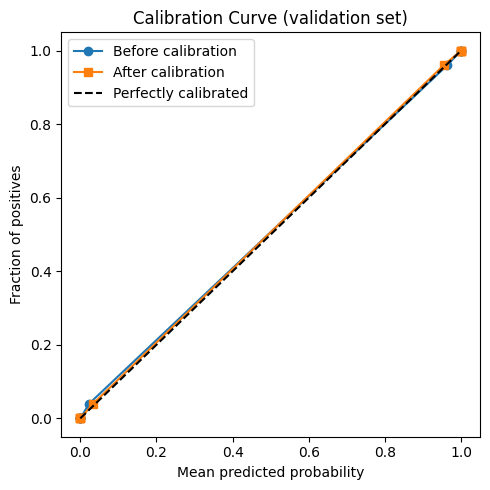

In [41]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(5, 5))
for probs, label, style in [
    (raw_val_probs, "Before calibration", "o-"),
    (calibrated_val_probs, "After calibration", "s-"),
]:
    frac_pos, mean_pred = calibration_curve(val_labels_t.numpy(), probs, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, style, label=label)
ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.set_title("Calibration Curve (validation set)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CFG.OUT_DIR, "calibration_curve.png"), dpi=120)
plt.show()

## STEP 19 — FINAL Test Evaluation (test set touched here for the first and only time)

In [42]:
test_logits_t, test_labels_t = collect_logits(final_model, test_loader)
test_raw_probs = torch.sigmoid(test_logits_t).numpy()
test_cal_probs = calibrated_probability(test_logits_t).numpy()
test_labels_np = test_labels_t.numpy()

test_preds = (test_raw_probs >= selected_threshold).astype(int)

test_accuracy  = accuracy_score(test_labels_np, test_preds)
test_precision = precision_score(test_labels_np, test_preds, zero_division=0)
test_recall    = recall_score(test_labels_np, test_preds, zero_division=0)
test_f1        = f1_score(test_labels_np, test_preds, zero_division=0)
test_auc       = roc_auc_score(test_labels_np, test_raw_probs) if len(set(test_labels_np.tolist())) > 1 else float("nan")
cm             = confusion_matrix(test_labels_np, test_preds)
report_txt     = classification_report(test_labels_np, test_preds, target_names=CLASS_NAMES)

damage_idx = CLASS_TO_IDX[[c for c in CLASS_NAMES if "no" not in c.lower()][0]]
damage_mask = test_labels_np == damage_idx
damage_recall = recall_score(test_labels_np, test_preds, pos_label=damage_idx, zero_division=0)
false_negatives = int(((test_preds == 1 - damage_idx) & damage_mask).sum()) if damage_idx == 1 else \
                   int(((test_preds != damage_idx) & damage_mask).sum())

test_brier_before = brier_score_loss(test_labels_np, test_raw_probs)
test_brier_after  = brier_score_loss(test_labels_np, test_cal_probs)

print("========== FINAL TEST METRICS ==========")
print(f"Accuracy      : {test_accuracy:.4f}")
print(f"Precision     : {test_precision:.4f}")
print(f"Recall        : {test_recall:.4f}")
print(f"F1            : {test_f1:.4f}")
print(f"ROC-AUC       : {test_auc:.4f}")
print(f"Damage Recall : {damage_recall:.4f}")
print(f"False Negatives (missed damage): {false_negatives}")
print(f"Brier (raw)   : {test_brier_before:.4f}")
print(f"Brier (calib) : {test_brier_after:.4f}")
print("\nConfusion matrix:\n", cm)
print("\nClassification report:\n", report_txt)

========== FINAL TEST METRICS ==========
Accuracy      : 0.9945
Precision     : 0.9901
Recall        : 0.9990
F1            : 0.9945
ROC-AUC       : 0.9998
Damage Recall : 0.9900
False Negatives (missed damage): 10
Brier (raw)   : 0.0043
Brier (calib) : 0.0043

Confusion matrix:
 [[990  10]
 [  1 999]]

Classification report:
               precision    recall  f1-score   support

      damage       1.00      0.99      0.99      1000
   no_damage       0.99      1.00      0.99      1000

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



## STEP 20 — Confusion Matrix, ROC & PR Curves

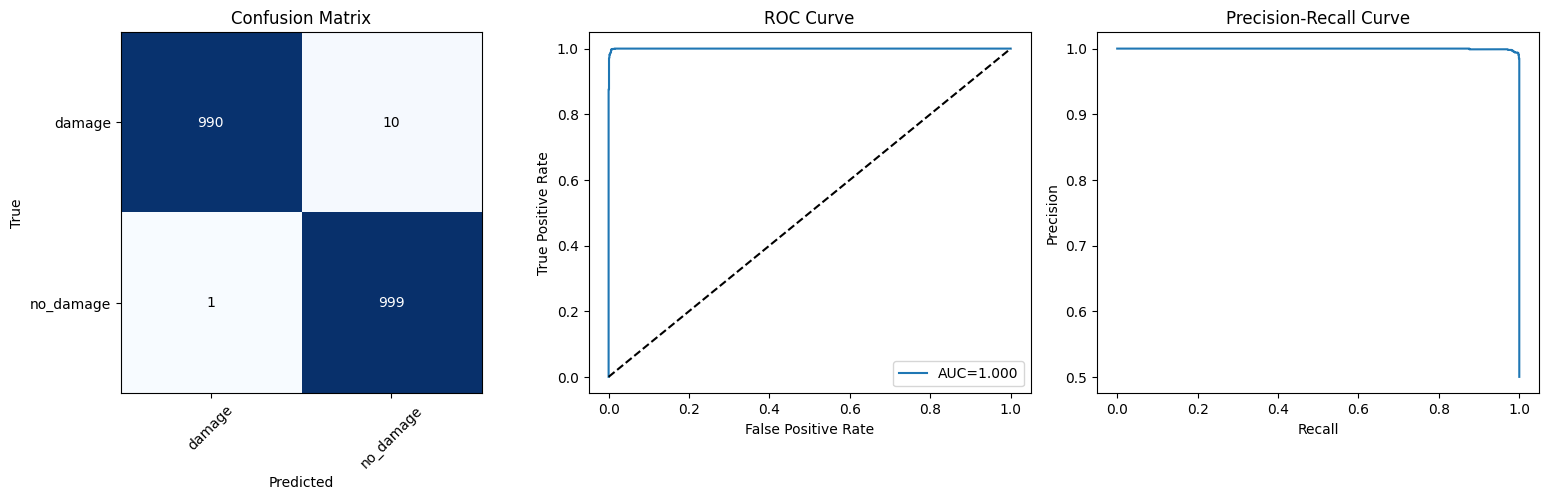

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Confusion matrix
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks(range(len(CLASS_NAMES))); axes[0].set_xticklabels(CLASS_NAMES, rotation=45)
axes[0].set_yticks(range(len(CLASS_NAMES))); axes[0].set_yticklabels(CLASS_NAMES)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].set_title("Confusion Matrix")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")

# ROC
fpr, tpr, _ = roc_curve(test_labels_np, test_raw_probs)
axes[1].plot(fpr, tpr, label=f"AUC={test_auc:.3f}")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve"); axes[1].legend()

# PR
prec, rec, _ = precision_recall_curve(test_labels_np, test_raw_probs)
axes[2].plot(rec, prec)
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.savefig(os.path.join(CFG.OUT_DIR, "test_curves.png"), dpi=120)
plt.show()

## STEP 21 — Test-Time Augmentation (TTA) Uncertainty Estimation

In [45]:
def tta_predict(model, pil_image, n_variants=4):
    """Original, h-flip, v-flip, mild rotation. Returns (mean_prob, std_prob)."""
    variants = [
        pil_image,
        pil_image.transpose(Image.FLIP_LEFT_RIGHT),
        pil_image.transpose(Image.FLIP_TOP_BOTTOM),
        pil_image.rotate(10),
    ][:n_variants]

    model.eval()
    probs = []
    with torch.no_grad():
        for v in variants:
            x = eval_transform(v).unsqueeze(0).to(DEVICE)
            logit = model(x).squeeze()
            p = torch.sigmoid(logit / learned_temperature).item()
            probs.append(p)
    probs = np.array(probs)
    return float(probs.mean()), float(probs.std())

# Demo on a handful of test images
demo_rows = test_df.sample(min(5, len(test_df)), random_state=CFG.SEED)
print(f"{'file':40s} {'true':10s} {'tta_mean':>9s} {'tta_std':>8s}")
for _, row in demo_rows.iterrows():
    with Image.open(row["path"]) as im:
        im = im.convert("RGB")
        mean_p, std_p = tta_predict(final_model, im)
    print(f"{os.path.basename(row['path'])[:38]:40s} {row['class']:10s} {mean_p:9.3f} {std_p:8.3f}")

file                                     true        tta_mean  tta_std
-95.636975_29.863702000000004.jpeg       no_damage      1.000    0.000
-93.6654_30.140094.jpeg                  damage         0.000    0.000
-95.64081800000001_29.771433000000002.   no_damage      1.000    0.000
-96.995373_28.619082000000002.jpeg       damage         0.005    0.006
-95.63293_29.845289.jpeg                 no_damage      1.000    0.000


## STEP 22 — Grad-CAM

Grad-CAM highlights image regions that most influenced the model's prediction.
It is an **attention/explanation visualization only** — not a building-damage
segmentation mask.

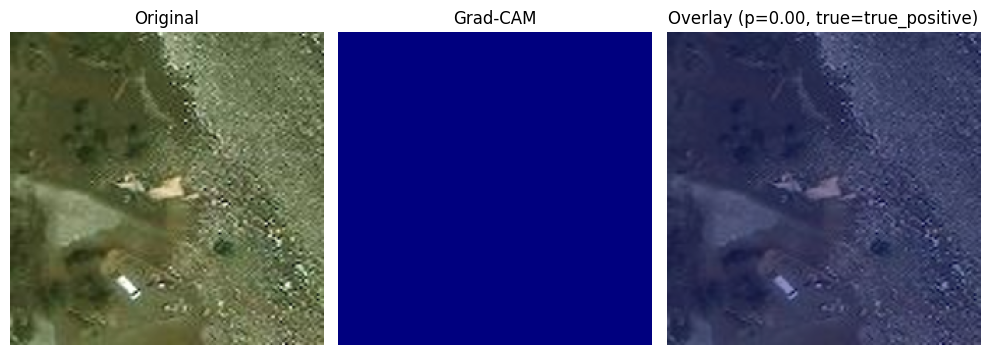

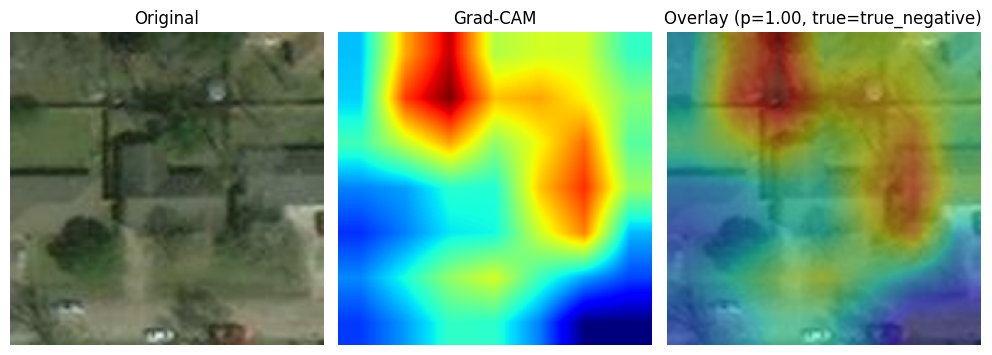

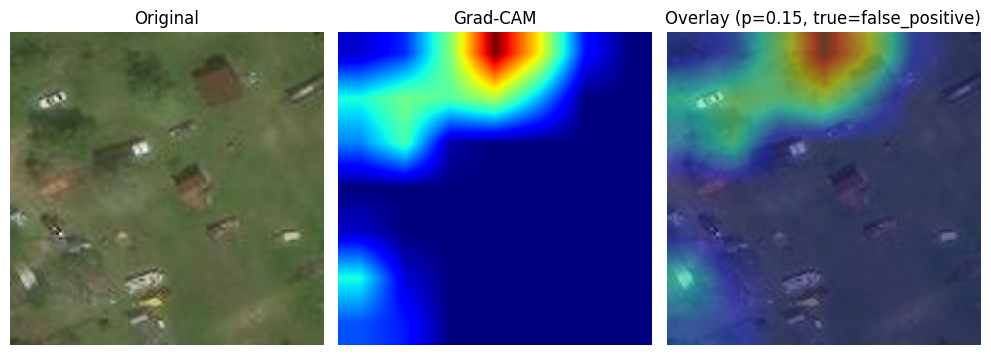

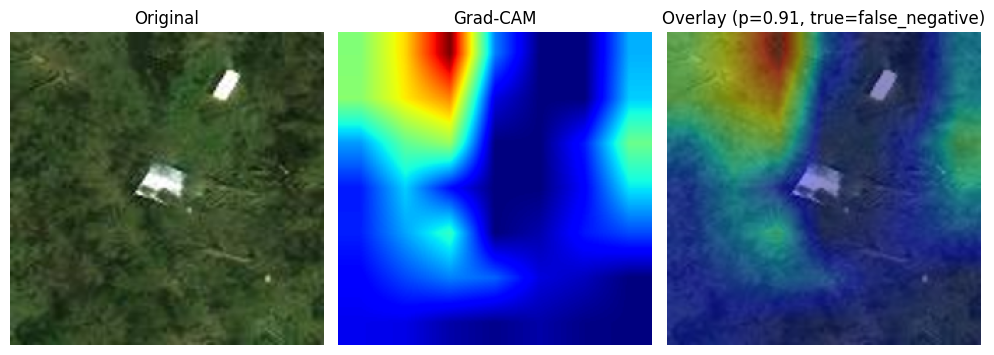

In [46]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def __call__(self, x):
        self.model.zero_grad()
        logit = self.model(x).squeeze()
        logit.backward(retain_graph=True)
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = cam / (cam.max() + 1e-8)
        cam = torch.nn.functional.interpolate(cam, size=(CFG.IMG_SIZE, CFG.IMG_SIZE), mode="bilinear", align_corners=False)
        return cam.squeeze().cpu().numpy(), torch.sigmoid(logit / learned_temperature).item()

# EfficientNet-B0's last conv block is a good Grad-CAM target
target_layer = final_model.features[-1]
gradcam = GradCAM(final_model, target_layer)

def show_gradcam(image_path, true_label):
    with Image.open(image_path) as im:
        im = im.convert("RGB")
    x = eval_transform(im).unsqueeze(0).to(DEVICE)
    x.requires_grad_(True)
    cam, prob = gradcam(x)

    orig_resized = im.resize((CFG.IMG_SIZE, CFG.IMG_SIZE))
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    axes[0].imshow(orig_resized); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(cam, cmap="jet"); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
    axes[2].imshow(orig_resized); axes[2].imshow(cam, cmap="jet", alpha=0.45); axes[2].axis("off")
    axes[2].set_title(f"Overlay (p={prob:.2f}, true={true_label})")
    plt.tight_layout()
    return fig

# Find one example of each case: TP, TN, FP, FN
test_df_reset = test_df.reset_index(drop=True)
case_rows = {"true_positive": None, "true_negative": None, "false_positive": None, "false_negative": None}
for i, row in test_df_reset.iterrows():
    true_idx = CLASS_TO_IDX[row["class"]]
    pred_idx = int(test_preds[i])
    if true_idx == damage_idx and pred_idx == damage_idx and case_rows["true_positive"] is None:
        case_rows["true_positive"] = row["path"]
    elif true_idx != damage_idx and pred_idx != damage_idx and case_rows["true_negative"] is None:
        case_rows["true_negative"] = row["path"]
    elif true_idx != damage_idx and pred_idx == damage_idx and case_rows["false_positive"] is None:
        case_rows["false_positive"] = row["path"]
    elif true_idx == damage_idx and pred_idx != damage_idx and case_rows["false_negative"] is None:
        case_rows["false_negative"] = row["path"]

for case, path in case_rows.items():
    if path is not None:
        fig = show_gradcam(path, case)
        fig.savefig(os.path.join(CFG.OUT_DIR, f"gradcam_{case}.png"), dpi=120)
        plt.show()
    else:
        print(f"No example found for case: {case}")

## STEP 23 — Failure Case Analysis

Total failures on test set: 11 / 2000
                                                                                                             path true_label predicted_label  damage_probability  calibrated_probability  uncertainty_std
         /kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/test/damage/-96.998209_28.632618.jpeg     damage       no_damage            0.999685                0.998342         0.004888
         /kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/test/damage/-96.985863_28.782155.jpeg     damage       no_damage            0.979823                0.956159         0.175097
         /kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/test/damage/-96.934568_28.496004.jpeg     damage       no_damage            0.947672                0.908824         0.059176
/kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/test/damage/-95.485584_29.770865999999998.jpeg     damage       no_damage            0.

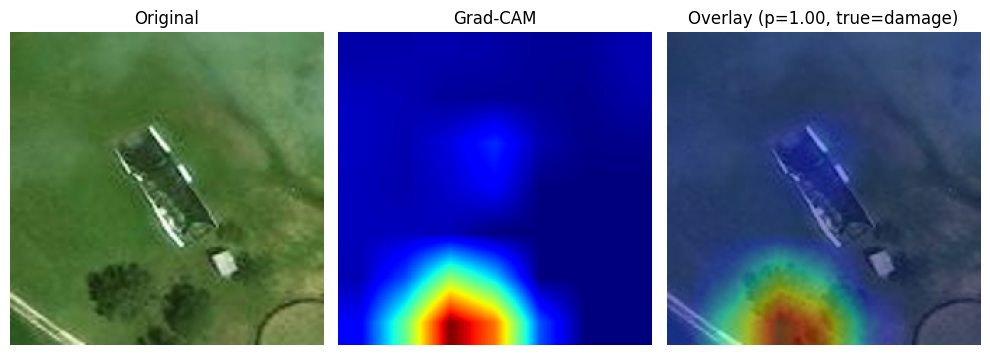

In [47]:
failure_records = []
for i, row in test_df_reset.iterrows():
    true_idx = CLASS_TO_IDX[row["class"]]
    pred_idx = int(test_preds[i])
    if true_idx != pred_idx:
        # recompute TTA + calibrated prob for this specific failure
        with Image.open(row["path"]) as im:
            im = im.convert("RGB")
            tta_mean, tta_std = tta_predict(final_model, im)
        failure_records.append({
            "path": row["path"],
            "true_label": row["class"],
            "predicted_label": CLASS_NAMES[pred_idx],
            "damage_probability": float(test_raw_probs[i]),
            "calibrated_probability": float(test_cal_probs[i]),
            "uncertainty_std": tta_std,
        })

failures_df = pd.DataFrame(failure_records)
print(f"Total failures on test set: {len(failures_df)} / {len(test_df_reset)}")
if len(failures_df):
    print(failures_df.sort_values("calibrated_probability", ascending=False).head(10).to_string(index=False))
    failures_df.to_csv(os.path.join(CFG.OUT_DIR, "failure_cases.csv"), index=False)

    # Show Grad-CAM for the highest-confidence wrong prediction, if any
    worst = failures_df.iloc[failures_df["calibrated_probability"].sub(0.5).abs().idxmax()]
    fig = show_gradcam(worst["path"], worst["true_label"])
    plt.show()

## STEP 24 — Visualizations: Class Distribution & Sample Images

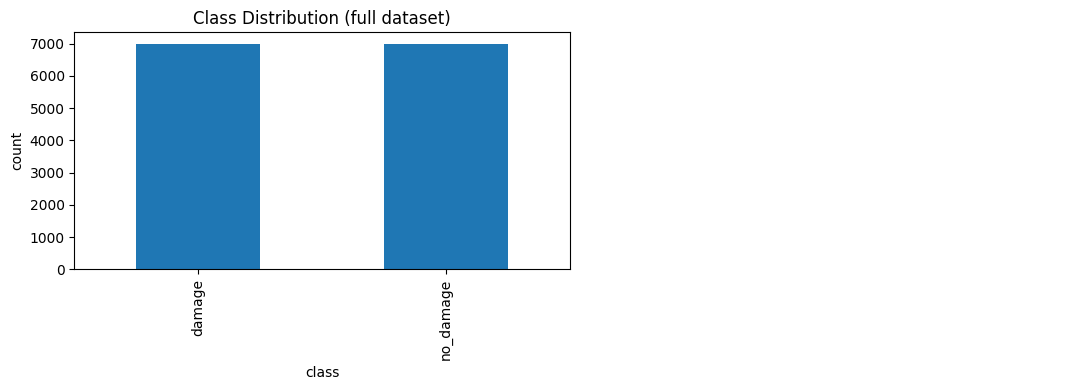

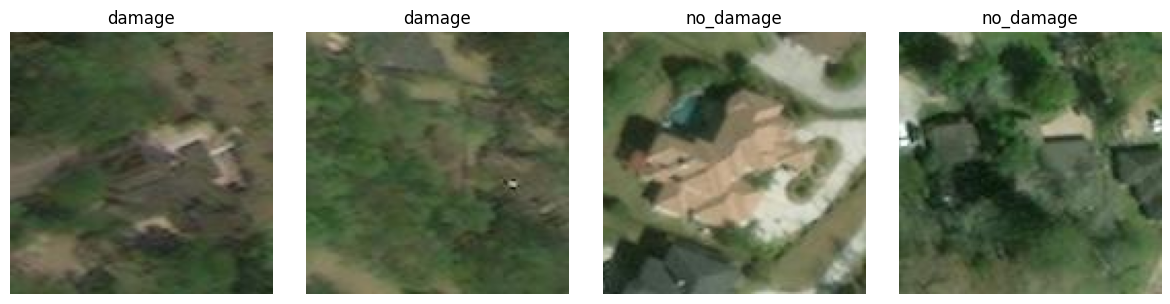

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_all["class"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Class Distribution (full dataset)")
axes[0].set_ylabel("count")

sample_paths = []
for cls in CLASS_NAMES:
    cls_rows = df_all[df_all["class"] == cls].sample(min(2, len(df_all[df_all["class"] == cls])), random_state=CFG.SEED)
    sample_paths.extend([(p, cls) for p in cls_rows["path"]])

axes[1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(CFG.OUT_DIR, "class_distribution.png"), dpi=120)
plt.show()

fig2, axes2 = plt.subplots(1, len(sample_paths), figsize=(3 * len(sample_paths), 3))
if len(sample_paths) == 1:
    axes2 = [axes2]
for ax, (p, cls) in zip(axes2, sample_paths):
    with Image.open(p) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(cls); ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(CFG.OUT_DIR, "sample_images.png"), dpi=120)
plt.show()

## STEP 25 — Training Curves (Loss / F1 / Recall)

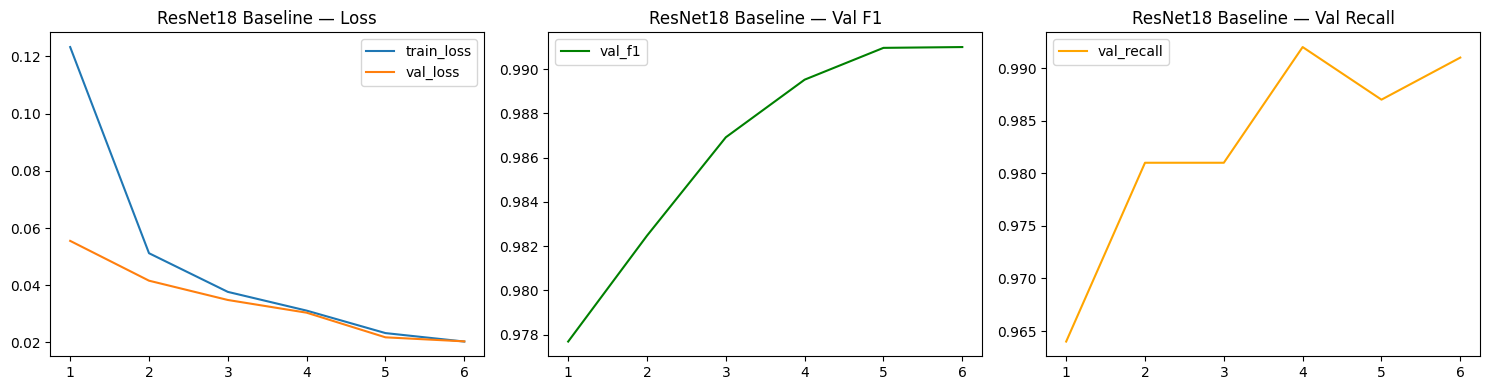

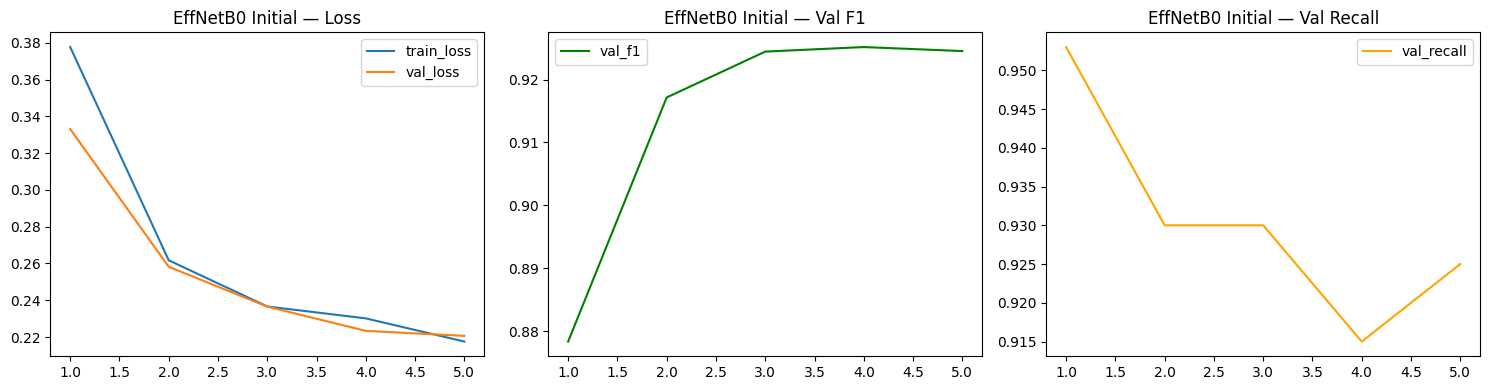

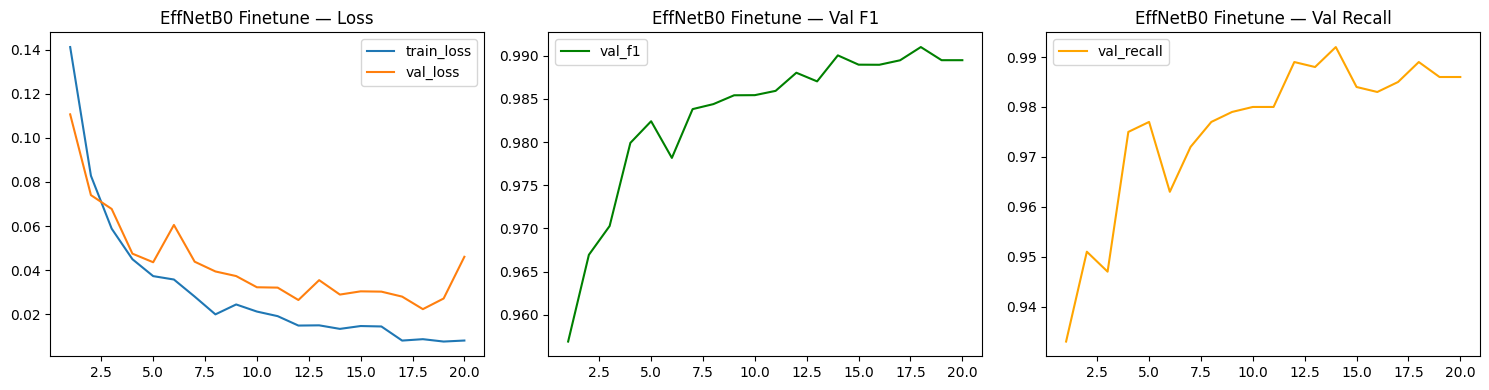

In [49]:
def plot_history(history, title):
    if not history:
        return
    hdf = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(hdf["epoch"], hdf["train_loss"], label="train_loss")
    axes[0].plot(hdf["epoch"], hdf["val_loss"], label="val_loss")
    axes[0].set_title(f"{title} — Loss"); axes[0].legend()

    axes[1].plot(hdf["epoch"], hdf["val_f1"], label="val_f1", color="green")
    axes[1].set_title(f"{title} — Val F1"); axes[1].legend()

    axes[2].plot(hdf["epoch"], hdf["val_recall"], label="val_recall", color="orange")
    axes[2].set_title(f"{title} — Val Recall"); axes[2].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(CFG.OUT_DIR, f"curves_{title.replace(' ', '_')}.png"), dpi=120)
    plt.show()

plot_history(resnet18_history, "ResNet18 Baseline")
plot_history(effnet_initial_history, "EffNetB0 Initial")
plot_history(effnet_ft_history, "EffNetB0 Finetune")

## STEP 26 — Save Final Deployment Artifacts

In [51]:
import datetime

torch.save(final_model.state_dict(), os.path.join(CFG.MODELS_DIR, "resqvision_efficientnet_b0.pt"))

with open(os.path.join(CFG.MODELS_DIR, "class_names.json"), "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

model_config = {
    "input_size": CFG.IMG_SIZE,
    "normalization_mean": CFG.MEAN,
    "normalization_std": CFG.STD,
    "model_name": "efficientnet_b0",
    "class_names": CLASS_NAMES,
    "threshold": selected_threshold,
    "training_date": datetime.datetime.utcnow().isoformat(),
    "model_version": "1.0.0",
}
with open(os.path.join(CFG.MODELS_DIR, "model_config.json"), "w") as f:
    json.dump(model_config, f, indent=2)

with open(os.path.join(CFG.MODELS_DIR, "calibration.json"), "w") as f:
    json.dump({"method": "temperature_scaling", "temperature": learned_temperature,
               "brier_before": test_brier_before, "brier_after": test_brier_after}, f, indent=2)

with open(os.path.join(CFG.MODELS_DIR, "threshold.json"), "w") as f:
    json.dump({"default_threshold": DEFAULT_THRESHOLD, "selected_threshold": selected_threshold,
               "validation_f1_at_selected": selected_val_f1}, f, indent=2)

final_metrics = {
    "test_accuracy": test_accuracy, "test_precision": test_precision, "test_recall": test_recall,
    "test_f1": test_f1, "test_auc": test_auc, "damage_recall": damage_recall,
    "false_negatives": false_negatives, "confusion_matrix": cm.tolist(),
}
with open(os.path.join(CFG.MODELS_DIR, "metrics.json"), "w") as f:
    json.dump(final_metrics, f, indent=2)

print("Artifacts saved to:", CFG.MODELS_DIR)
print(os.listdir(CFG.MODELS_DIR))

Artifacts saved to: resqvision_artifacts/models
['resqvision_efficientnet_b0.pt', 'threshold.json', 'class_names.json', 'calibration.json', 'metrics.json', 'best_resnet18.pt', 'model_config.json', 'best_efficientnet_finetuned.pt', 'best_efficientnet_initial.pt']


/tmp/ipykernel_58/2042996848.py:15: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "training_date": datetime.datetime.utcnow().isoformat(),


## STEP 27 — Reusable Inference Function (independent of training code)

In [52]:
def predict_image(image_path, model=final_model, threshold=None, temperature=None):
    """Standalone inference. Returns a RESQVISION-Priority-Engine-ready dict."""
    threshold = threshold if threshold is not None else selected_threshold
    temperature = temperature if temperature is not None else learned_temperature

    with Image.open(image_path) as im:
        im = im.convert("RGB")

    model.eval()
    x = eval_transform(im).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logit = model(x).squeeze()
        raw_prob = torch.sigmoid(logit).item()
        cal_prob = torch.sigmoid(logit / temperature).item()

    tta_mean, tta_std = tta_predict(model, im)

    damage_label = [c for c in CLASS_NAMES if "no" not in c.lower()][0]
    no_damage_label = [c for c in CLASS_NAMES if "no" in c.lower()][0]
    prediction = damage_label if raw_prob >= threshold else no_damage_label

    if tta_std < 0.05:
        confidence_level = "high"
    elif tta_std < 0.15:
        confidence_level = "medium"
    else:
        confidence_level = "low"

    return {
        "prediction": prediction,
        "damage_probability": round(raw_prob, 4),
        "calibrated_probability": round(cal_prob, 4),
        "uncertainty": round(tta_std, 4),
        "confidence_level": confidence_level,
        "model_version": model_config["model_version"],
    }

# Demo
demo_path = test_df.iloc[0]["path"]
print("Sample inference on:", demo_path)
print(predict_image(demo_path))

Sample inference on: /kaggle/input/datasets/kmader/satellite-images-of-hurricane-damage/test/damage/-96.87984300000001_28.499421999999996.jpeg
{'prediction': 'no_damage', 'damage_probability': 0.0, 'calibrated_probability': 0.0, 'uncertainty': 0.0001, 'confidence_level': 'high', 'model_version': '1.0.0'}


## STEP 28 — Experiment Summary

In [53]:
experiments = pd.DataFrame([
    {
        "experiment": "1. ResNet-18 baseline", "epochs_run": len(resnet18_history),
        "batch_size": BATCH_SIZE, "lr": 1e-4, "optimizer": "AdamW",
        "val_f1": resnet18_val_metrics["f1"], "val_recall": resnet18_val_metrics["recall"],
        "val_auc": resnet18_val_metrics["auc"], "training_time_s": resnet18_time,
    },
    {
        "experiment": "2. EfficientNet-B0 initial", "epochs_run": len(effnet_initial_history),
        "batch_size": BATCH_SIZE, "lr": CFG.EFFNET_INITIAL_LR, "optimizer": "AdamW",
        "val_f1": effnet_val_metrics["f1"], "val_recall": effnet_val_metrics["recall"],
        "val_auc": effnet_val_metrics["auc"], "training_time_s": effnet_initial_time,
    },
    {
        "experiment": "3. EfficientNet-B0 fine-tuned", "epochs_run": len(effnet_ft_history),
        "batch_size": BATCH_SIZE, "lr": CFG.EFFNET_FT_LR, "optimizer": "AdamW",
        "val_f1": effnet_ft_best_f1, "val_recall": val_metrics_final["recall"],
        "val_auc": val_metrics_final["auc"], "training_time_s": effnet_ft_time,
    },
])
experiments["test_f1"] = [None, None, test_f1]
experiments["test_recall"] = [None, None, test_recall]
experiments["test_auc"] = [None, None, test_auc]
print(experiments.to_string(index=False))
experiments.to_csv(os.path.join(CFG.OUT_DIR, "experiment_summary.csv"), index=False)

                   experiment  epochs_run  batch_size     lr optimizer   val_f1  val_recall  val_auc  training_time_s  test_f1  test_recall  test_auc
        1. ResNet-18 baseline           6          64 0.0001     AdamW 0.991000       0.991 0.999759       155.503896      NaN          NaN       NaN
   2. EfficientNet-B0 initial           5          64 0.0010     AdamW 0.925177       0.915 0.975503       123.906430      NaN          NaN       NaN
3. EfficientNet-B0 fine-tuned          20          64 0.0001     AdamW 0.990982       0.989 0.999748       482.436473 0.994525        0.999  0.999773


## STEP 29 — Inference Speed Benchmark

In [54]:
n_bench = min(50, len(test_df))
bench_paths = test_df["path"].tolist()[:n_bench]

t0 = time.time()
for p in bench_paths:
    _ = predict_image(p)
t1 = time.time()
avg_inf_time_ms = (t1 - t0) / max(n_bench, 1) * 1000
print(f"Average inference time/image (incl. TTA): {avg_inf_time_ms:.1f} ms over {n_bench} images")

Average inference time/image (incl. TTA): 50.2 ms over 50 images


## STEP 30 — FINAL REPORT

In [55]:
print("=" * 42)
print("RESQVISION MODEL TRAINING REPORT")
print("=" * 42)
print(f"Dataset total : {len(df_all)}")
print(f"  Train       : {len(train_df)}")
print(f"  Validation  : {len(val_df)}")
print(f"  Test        : {len(test_df)}")
print(f"Device        : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU           : {torch.cuda.get_device_name(0)}")
print()
print("Baseline (ResNet-18)")
print(f"  Val F1      : {resnet18_val_metrics['f1']:.4f}")
print(f"  Val Recall  : {resnet18_val_metrics['recall']:.4f}")
print(f"  Val AUC     : {resnet18_val_metrics['auc']:.4f}")
print(f"  Train time  : {resnet18_time:.1f}s")
print()
print("Final Model (EfficientNet-B0, {})".format(FINAL_MODEL_NAME))
print(f"  Val F1      : {val_metrics_final['f1']:.4f}")
print(f"  Val Recall  : {val_metrics_final['recall']:.4f}")
print(f"  Val AUC     : {val_metrics_final['auc']:.4f}")
print(f"  Train time  : {effnet_initial_time + effnet_ft_time:.1f}s "
      f"(initial {effnet_initial_time:.1f}s + fine-tune {effnet_ft_time:.1f}s)")
print()
print("Final Test Evaluation")
print(f"  Accuracy    : {test_accuracy:.4f}")
print(f"  Precision   : {test_precision:.4f}")
print(f"  Recall      : {test_recall:.4f}")
print(f"  F1          : {test_f1:.4f}")
print(f"  ROC-AUC     : {test_auc:.4f}")
print(f"  Damage Recall     : {damage_recall:.4f}")
print(f"  False Negatives   : {false_negatives}")
print()
print("Calibration (Brier score)")
print(f"  Before      : {test_brier_before:.4f}")
print(f"  After       : {test_brier_after:.4f}")
print()
print(f"Best Threshold        : {selected_threshold:.2f}")
print(f"Avg Inference Time    : {avg_inf_time_ms:.1f} ms/image")
print()
print("Model saved to:", os.path.join(CFG.MODELS_DIR, "resqvision_efficientnet_b0.pt"))
print()
print("NOTE: This model is a binary VISIBLE-DAMAGE classifier only.")
print("It does NOT perform segmentation, survivor detection, or rescue")
print("prioritization. Priority scoring is computed downstream by the")
print("RESQVISION Priority Engine using damage_probability, calibrated_probability,")
print("and uncertainty as inputs.")

RESQVISION MODEL TRAINING REPORT
Dataset total : 14000
  Train       : 10000
  Validation  : 2000
  Test        : 2000
Device        : cuda
GPU           : Tesla T4

Baseline (ResNet-18)
  Val F1      : 0.9910
  Val Recall  : 0.9910
  Val AUC     : 0.9998
  Train time  : 155.5s

Final Model (EfficientNet-B0, efficientnet_finetuned)
  Val F1      : 0.9910
  Val Recall  : 0.9890
  Val AUC     : 0.9997
  Train time  : 606.3s (initial 123.9s + fine-tune 482.4s)

Final Test Evaluation
  Accuracy    : 0.9945
  Precision   : 0.9901
  Recall      : 0.9990
  F1          : 0.9945
  ROC-AUC     : 0.9998
  Damage Recall     : 0.9900
  False Negatives   : 10

Calibration (Brier score)
  Before      : 0.0043
  After       : 0.0043

Best Threshold        : 0.37
Avg Inference Time    : 50.2 ms/image

Model saved to: resqvision_artifacts/models/resqvision_efficientnet_b0.pt

NOTE: This model is a binary VISIBLE-DAMAGE classifier only.
It does NOT perform segmentation, survivor detection, or rescue
prio